In [14]:
%pip install pandas numpy matplotlib scikit-learn tensorflow joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [15]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

In [16]:
PROJECT_DIR = ".."

TRAIN_PATH = os.path.join(
    PROJECT_DIR, "data", "processed", "train_FD001_processed.csv"
)

TEST_PATH = os.path.join(
    PROJECT_DIR, "data", "processed", "test_FD001_processed.csv"
)

RUL_PATH = os.path.join(
    PROJECT_DIR, "data", "raw", "RUL_FD001.txt"
)

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

print(train_df.head())
print(test_df.head())

Training shape: (20631, 20)
Testing shape: (13096, 19)
   engine_id  cycle  op_setting_1  op_setting_2  op_setting_3  sensor_2  \
0          1      1       -0.0007       -0.0004         100.0    641.82   
1          1      2        0.0019       -0.0003         100.0    642.15   
2          1      3       -0.0043        0.0003         100.0    642.35   
3          1      4        0.0007        0.0000         100.0    642.35   
4          1      5       -0.0019       -0.0002         100.0    642.37   

   sensor_3  sensor_4  sensor_7  sensor_8  sensor_9  sensor_11  sensor_12  \
0   1589.70   1400.60    554.36   2388.06   9046.19      47.47     521.66   
1   1591.82   1403.14    553.75   2388.04   9044.07      47.49     522.28   
2   1587.99   1404.20    554.26   2388.08   9052.94      47.27     522.42   
3   1582.79   1401.87    554.45   2388.11   9049.48      47.13     522.86   
4   1582.85   1406.22    554.00   2388.06   9055.15      47.28     522.19   

   sensor_13  sensor_14  sensor

In [17]:
def standardize_columns(df):
    df = df.copy()

    df.columns = [
        str(col).strip().lower().replace(" ", "_")
        for col in df.columns
    ]

    aliases = {
        "unit": "engine_id",
        "engine": "engine_id",
        "time": "cycle",
        "time_in_cycles": "cycle",
        "op_setting_1": "setting_1",
        "op_setting_2": "setting_2",
        "op_setting_3": "setting_3"
    }

    df = df.rename(columns=aliases)

    df = df.loc[
        :, ~df.columns.astype(str).str.startswith("unnamed:")
    ]

    df = df.loc[:, ~df.columns.duplicated()]

    return df


train_df = standardize_columns(train_df)
test_df = standardize_columns(test_df)

print(train_df.columns.tolist())
RUL_CAP = 125

train_df["RUL_capped"] = train_df["rul"].clip(upper=RUL_CAP)

print(train_df[["engine_id", "cycle", "rul", "RUL_capped"]].head())

['engine_id', 'cycle', 'setting_1', 'setting_2', 'setting_3', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21', 'rul']
   engine_id  cycle  rul  RUL_capped
0          1      1  191         125
1          1      2  190         125
2          1      3  189         125
3          1      4  188         125
4          1      5  187         125


In [18]:
feature_cols = [
    col for col in train_df.columns
    if col.startswith("sensor_")
    or col.startswith("setting_")
]

print("Number of features:", len(feature_cols))
print(feature_cols)
constant_cols = [
    col for col in feature_cols
    if train_df[col].nunique() <= 1
]

feature_cols = [
    col for col in feature_cols
    if col not in constant_cols
]

print("Removed constant features:", constant_cols)
print("Features retained:", len(feature_cols))

Number of features: 17
['setting_1', 'setting_2', 'setting_3', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
Removed constant features: ['setting_3']
Features retained: 16


In [19]:
engine_ids = train_df["engine_id"].unique()

train_engines, val_engines = train_test_split(
    engine_ids,
    test_size=0.2,
    random_state=42
)

train_part = train_df[
    train_df["engine_id"].isin(train_engines)
].copy()

val_part = train_df[
    train_df["engine_id"].isin(val_engines)
].copy()

scaler = StandardScaler()

train_part = train_part.copy()
train_part[feature_cols] = train_part[feature_cols].astype(float)
train_part.loc[:, feature_cols] = scaler.fit_transform(train_part[feature_cols])

val_part = val_part.copy()
val_part[feature_cols] = val_part[feature_cols].astype(float)
val_part.loc[:, feature_cols] = scaler.transform(val_part[feature_cols])

test_df[feature_cols] = test_df[feature_cols].astype(float)
test_df.loc[:, feature_cols] = scaler.transform(test_df[feature_cols])

print("Training engines:", len(train_engines))
print("Validation engines:", len(val_engines))

Training engines: 80
Validation engines: 20


In [20]:
WINDOW_SIZE = 30


def create_sequences(df, features, target_col=None,
                     window_size=30, last_only=False):

    X, y = [], []

    for engine_id, engine_df in df.groupby("engine_id"):

        engine_df = engine_df.sort_values("cycle")

        values = engine_df[features].to_numpy()

        if target_col is not None:
            targets = engine_df[target_col].to_numpy()

        if last_only:
            end_positions = [len(values) - 1]
        else:
            end_positions = range(len(values))

        for end in end_positions:

            start = max(0, end - window_size + 1)
            sequence = values[start:end + 1]

            # Pad early sequences to the required window size
            if len(sequence) < window_size:
                padding = np.repeat(
                    sequence[0:1],
                    window_size - len(sequence),
                    axis=0
                )

                sequence = np.concatenate(
                    [padding, sequence],
                    axis=0
                )

            X.append(sequence)

            if target_col is not None:
                y.append(targets[end])

    X = np.asarray(X, dtype=np.float32)

    if target_col is not None:
        y = np.asarray(y, dtype=np.float32)
        return X, y

    return X
X_train, y_train = create_sequences(
    train_part,
    feature_cols,
    target_col="RUL_capped",
    window_size=WINDOW_SIZE
)

X_val, y_val = create_sequences(
    val_part,
    feature_cols,
    target_col="RUL_capped",
    window_size=WINDOW_SIZE
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

X_train: (16561, 30, 16)
y_train: (16561,)
X_val: (4070, 30, 16)
y_val: (4070,)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        20,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,697 (131.63 KB)

 Trainable params: 33,697 (131.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 7s 32ms/step - loss: 7526.7832 - mae: 76.8022 - val_loss: 5663.1484 - val_mae: 64.9576
Epoch 2/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - loss: 4041.6113 - mae: 53.5656 - val_loss: 2431.1777 - val_mae: 40.6427
Epoch 3/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - loss: 1518.6774 - mae: 31.8291 - val_loss: 760.2311 - val_mae: 22.7789
Epoch 4/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 533.5822 - mae: 18.9114 - val_loss: 310.5329 - val_mae: 14.9360
Epoch 5/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 297.9290 - mae: 13.5949 - val_loss: 195.3488 - val_mae: 11.1974
Epoch 6/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - loss: 219.0998 - mae: 11.2222 - val_loss: 158.3226 - val_mae: 9.3970
Epoch 7/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - loss: 196.7677 - mae: 10.5077 - val_loss: 155.2863 - val_mae: 8.8361
Epoch 8/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - loss: 179.2886 - mae: 10.0529 - val_loss: 176.9902 - val_mae: 9.385

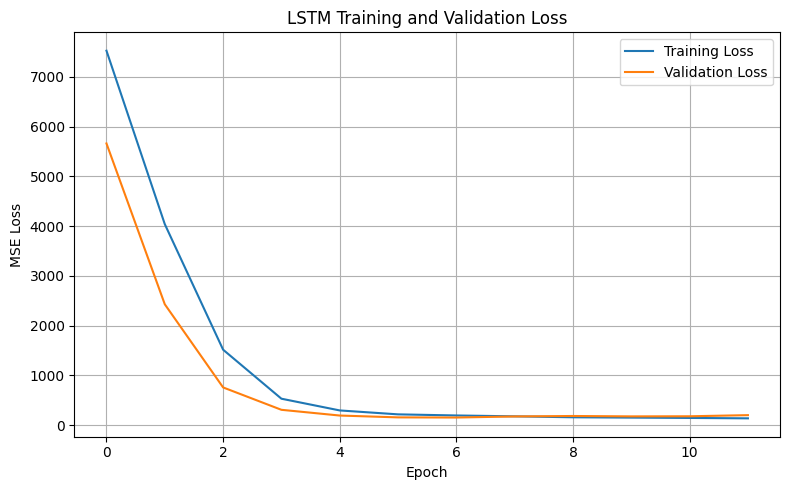

In [21]:
model = Sequential([
    Input(shape=(WINDOW_SIZE, len(feature_cols))),

    LSTM(64, return_sequences=True),
    Dropout(0.2),

    LSTM(32),
    Dropout(0.2),

    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=128,
    callbacks=[early_stopping],
    verbose=1
)
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("LSTM Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig(
    os.path.join(PROJECT_DIR, "results", "figures",
                 "lstm_training_loss.png"),
    dpi=300
)

plt.show()
os.makedirs(
    os.path.join(PROJECT_DIR, "results", "figures"),
    exist_ok=True
)

os.makedirs(
    os.path.join(PROJECT_DIR, "results", "metrics"),
    exist_ok=True
)

os.makedirs(
    os.path.join(PROJECT_DIR, "models"),
    exist_ok=True
)

In [22]:
val_predictions = model.predict(X_val).flatten()

val_mae = mean_absolute_error(
    y_val, val_predictions
)

val_rmse = np.sqrt(
    mean_squared_error(y_val, val_predictions)
)

val_r2 = r2_score(
    y_val, val_predictions
)

print("Validation MAE:", round(val_mae, 3))
print("Validation RMSE:", round(val_rmse, 3))
print("Validation R2:", round(val_r2, 3))

128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
Validation MAE: 8.836
Validation RMSE: 12.461
Validation R2: 0.911


In [23]:
rul_test = pd.read_csv(
    RUL_PATH,
    sep=r"\s+",
    header=None
).iloc[:, 0].to_numpy()

print("Number of test engines:", test_df["engine_id"].nunique())
print("Number of RUL labels:", len(rul_test))
X_test = create_sequences(
    test_df,
    feature_cols,
    window_size=WINDOW_SIZE,
    last_only=True
)

print("X_test:", X_test.shape)
test_predictions = model.predict(X_test).flatten()

print("First 10 predictions:")
print(np.round(test_predictions[:10], 2))
if len(test_predictions) != len(rul_test):
    raise ValueError(
        "Prediction count does not match the number of RUL labels."
    )

test_mae = mean_absolute_error(
    rul_test, test_predictions
)

test_rmse = np.sqrt(
    mean_squared_error(rul_test, test_predictions)
)

test_r2 = r2_score(
    rul_test, test_predictions
)

print("Test MAE:", round(test_mae, 3))
print("Test RMSE:", round(test_rmse, 3))
print("Test R2:", round(test_r2, 3))

Number of test engines: 100
Number of RUL labels: 100
X_test: (100, 30, 16)
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
First 10 predictions:
[118.55 120.76  45.21  82.3   98.27 116.21  97.78  99.51 120.79 101.39]
Test MAE: 10.962
Test RMSE: 15.188
Test R2: 0.866


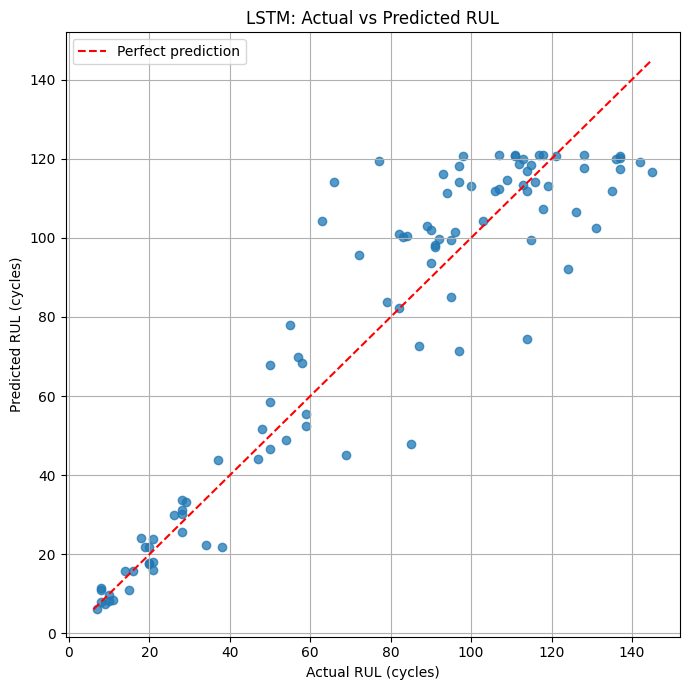

In [24]:
plt.figure(figsize=(7, 7))

plt.scatter(
    rul_test,
    test_predictions,
    alpha=0.75
)

lower = min(rul_test.min(), test_predictions.min())
upper = max(rul_test.max(), test_predictions.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual RUL (cycles)")
plt.ylabel("Predicted RUL (cycles)")
plt.title("LSTM: Actual vs Predicted RUL")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    os.path.join(
        PROJECT_DIR, "results", "figures",
        "lstm_actual_vs_predicted.png"
    ),
    dpi=300
)

plt.show()

In [25]:
model.save(
    os.path.join(PROJECT_DIR, "models", "lstm.keras")
)

joblib.dump(
    scaler,
    os.path.join(PROJECT_DIR, "models", "lstm_scaler.pkl")
)

joblib.dump(
    feature_cols,
    os.path.join(PROJECT_DIR, "models", "lstm_features.pkl")
)

metrics = pd.DataFrame([{
    "Model": "LSTM",
    "Window_Size": WINDOW_SIZE,
    "Features": len(feature_cols),
    "MAE": test_mae,
    "RMSE": test_rmse,
    "R2": test_r2
}])

metrics.to_csv(
    os.path.join(
        PROJECT_DIR, "results", "metrics",
        "lstm_metrics.csv"
    ),
    index=False
)

print("LSTM model, scaler, features and metrics saved.")

LSTM model, scaler, features and metrics saved.
